# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Muhammad Farid Wijdan | 5054251042 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
np.random.seed(42)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

print("Library berhasil diimpor.")


Library berhasil diimpor.


In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

import os

# Jalankan notebook dari folder yang sama dengan CSV; fallback ke path subfolder.
_csv = "Mall_Customers.csv"
if not os.path.exists(_csv):
    _csv = os.path.join("7. DBSCAN, BIRCH, EM", "Mall_Customers.csv")
print("Membaca:", _csv)

df = pd.read_csv(_csv)

print("Shape (baris, kolom):", df.shape)
print()
print("5 baris pertama:")
print(df.head().to_string())
print()
print("Tipe data:")
print(df.dtypes.to_string())
print()
print("Statistik deskriptif:")
print(df.describe().T.round(2).to_string())
print()
print("Jumlah missing value per kolom:")
print(df.isnull().sum().to_string())
print()
print("Jumlah baris duplikat:", int(df.duplicated().sum()))
print()
print("Distribusi Gender:")
print(df["Gender"].value_counts().to_string())


Membaca: Mall_Customers.csv
Shape (baris, kolom): (200, 5)

5 baris pertama:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Tipe data:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64

Statistik deskriptif:
                        count    mean    std   min    25%    50%     75%    max
CustomerID              200.0  100.50  57.88   1.0  50.75  100.5  150.25  200.0
Age                     200.0   38.85  13.97  18.0  28.75   36.0   49.00   70.0
Annual Income (k$)      200.0   60.56  26.26  15.0  41.50   61

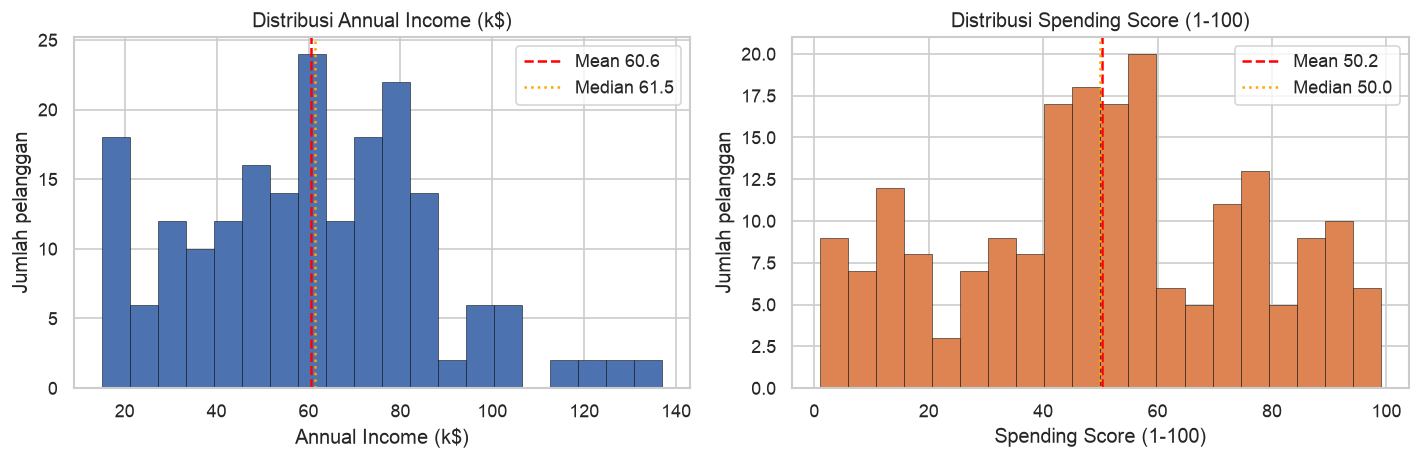

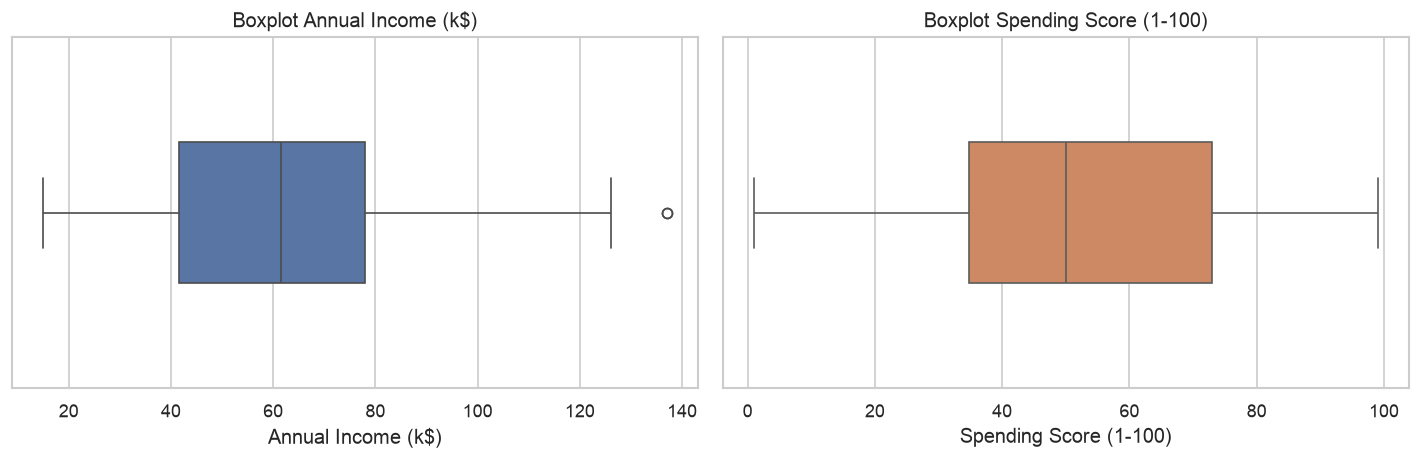

Annual Income (k$): min 15, max 137, mean 60.56, median 61.5, std 26.26
Spending Score (1-100): min 1, max 99, mean 50.20, median 50.0, std 25.82


In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Annual Income (k$)"], bins=20, color="#4C72B0", edgecolor="black", linewidth=0.3)
axes[0].axvline(df["Annual Income (k$)"].mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean {df['Annual Income (k$)'].mean():.1f}")
axes[0].axvline(df["Annual Income (k$)"].median(), color="orange", linestyle=":", linewidth=1.5, label=f"Median {df['Annual Income (k$)'].median():.1f}")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Jumlah pelanggan")
axes[0].set_title("Distribusi Annual Income (k$)")
axes[0].legend()

axes[1].hist(df["Spending Score (1-100)"], bins=20, color="#DD8452", edgecolor="black", linewidth=0.3)
axes[1].axvline(df["Spending Score (1-100)"].mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean {df['Spending Score (1-100)'].mean():.1f}")
axes[1].axvline(df["Spending Score (1-100)"].median(), color="orange", linestyle=":", linewidth=1.5, label=f"Median {df['Spending Score (1-100)'].median():.1f}")
axes[1].set_xlabel("Spending Score (1-100)")
axes[1].set_ylabel("Jumlah pelanggan")
axes[1].set_title("Distribusi Spending Score (1-100)")
axes[1].legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["Annual Income (k$)"], ax=axes[0], color="#4C72B0", width=0.4)
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_title("Boxplot Annual Income (k$)")

sns.boxplot(x=df["Spending Score (1-100)"], ax=axes[1], color="#DD8452", width=0.4)
axes[1].set_xlabel("Spending Score (1-100)")
axes[1].set_title("Boxplot Spending Score (1-100)")

plt.tight_layout()
plt.show()

print(f"Annual Income (k$): min {df['Annual Income (k$)'].min()}, max {df['Annual Income (k$)'].max()}, mean {df['Annual Income (k$)'].mean():.2f}, median {df['Annual Income (k$)'].median():.1f}, std {df['Annual Income (k$)'].std():.2f}")
print(f"Spending Score (1-100): min {df['Spending Score (1-100)'].min()}, max {df['Spending Score (1-100)'].max()}, mean {df['Spending Score (1-100)'].mean():.2f}, median {df['Spending Score (1-100)'].median():.1f}, std {df['Spending Score (1-100)'].std():.2f}")


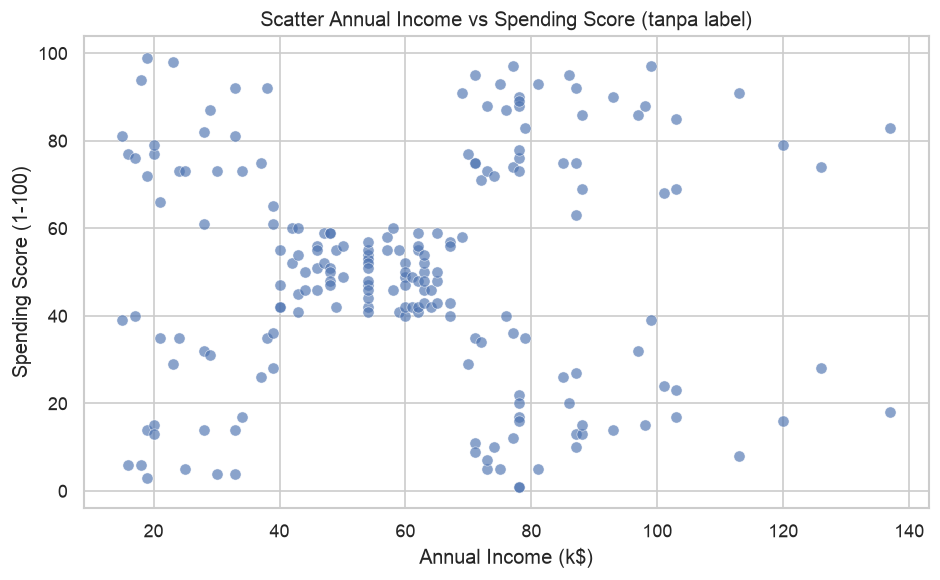

Korelasi Pearson Income vs Spending Score: 0.0099


In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 5))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.65, s=45, color="#4C72B0", edgecolors="white", linewidths=0.4,
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Scatter Annual Income vs Spending Score (tanpa label)")
plt.tight_layout()
plt.show()

korelasi = df["Annual Income (k$)"].corr(df["Spending Score (1-100)"])
print(f"Korelasi Pearson Income vs Spending Score: {korelasi:.4f}")


## Pertanyaan EDA

**Jawaban (berdasarkan output cell di atas):**

- **Missing value & duplikat:** tidak ada. Dari 200 baris x 5 kolom, semua kolom (`CustomerID`, `Gender`, `Age`, `Annual Income (k$)`, `Spending Score (1-100)`) memiliki 0 missing value, dan `df.duplicated().sum()` = 0. Jadi saya tidak perlu mengimputasi atau menghapus baris untuk tahap clustering ini.
- **Rentang pendapatan:** `Annual Income (k$)` berkisar 15-137 (mean 60.56, median 61.5, std 26.26). Artinya mayoritas pelanggan berpendapatan sekitar 40-80 ribu dolar per tahun, dengan ekor kanan menuju 100+ (semua pendapatan > 100 k$ hanya sekitar 8 orang dari 200).
- **Rentang spending score:** 1-99 (mean 50.2, median 50.0, std 25.82). Distribusinya hampir datar/seragam di seluruh rentang 0-100, tidak menumpuk di satu ujung. Satu-satunya nilai ekstrem yang terlihat di boxplot adalah skor 1 sebagai outlier bawah.
- **Korelasi:** korelasi Pearson income vs spending hanya 0.01 — praktis nol. Artinya pelanggan kaya tidak selalu boros, dan pelanggan miskin tidak selalu hemat; kedua fitur ini membawa informasi yang saling melengkapi.
- **Apakah ada kelompok yang terpisah?** Dari scatter plot terlihat beberapa gugusan yang bisa diintip: (1) kelompok pendapatan rendah (~15-30 k$) yang menyebar di seluruh skor, (2) kelompok pendapatan menengah (~40-75 k$) yang menumpuk, dan (3) kelompok pendapatan tinggi (~100+) yang hanya ada beberapa titik. Terdapat juga area kosong di pojok pendapatan tinggi & skor menengah-bawah. Pola ini belum tajam seperti 4-5 cluster Mall Customers klasik, jadi clustering berbasis kepadatan atau campuran Gaussian perlu diuji lewat parameter.


# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

# Tidak ada missing/duplikat (cek ulang di sini), tapi tetap ditangani defensif:
df_clean = df.drop_duplicates().copy()
print("Baris setelah hapus duplikat:", df_clean.shape[0], "(awal:", df.shape[0], ")")

# Fitur clustering: hanya dua kolom numerik sesuai instruksi.
X = df_clean[["Annual Income (k$)", "Spending Score (1-100)"]].copy()

print("Shape X:", X.shape)
print()
print(X.head().to_string())
print()
print("Statistik X:")
print(X.describe().T.round(2).to_string())
assert X.isnull().sum().sum() == 0, "X masih mengandung missing value"
print()
print("X siap dipakai untuk clustering (CustomerID & Gender tidak dipakai sebagai fitur).")


Baris setelah hapus duplikat: 200 (awal: 200 )
Shape X: (200, 2)

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Statistik X:
                        count   mean    std   min    25%   50%   75%    max
Annual Income (k$)      200.0  60.56  26.26  15.0  41.50  61.5  78.0  137.0
Spending Score (1-100)  200.0  50.20  25.82   1.0  34.75  50.0  73.0   99.0

X siap dipakai untuk clustering (CustomerID & Gender tidak dipakai sebagai fitur).


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

print("5 baris pertama X_scaled:")
print(X_scaled.head().round(3).to_string())
print()
print("Statistik deskriptif X_scaled:")
print(X_scaled.describe().T.round(3).to_string())
print()
print("Rata-rata per kolom (harus ~0):", X_scaled.mean().round(4).to_dict())
print("Standar deviasi per kolom (harus ~1):", X_scaled.std(ddof=1).round(4).to_dict())


5 baris pertama X_scaled:
   Annual Income (k$)  Spending Score (1-100)
0              -1.739                  -0.435
1              -1.739                   1.196
2              -1.701                  -1.716
3              -1.701                   1.040
4              -1.663                  -0.396

Statistik deskriptif X_scaled:
                        count  mean    std    min    25%    50%    75%    max
Annual Income (k$)      200.0  -0.0  1.003 -1.739 -0.728  0.036  0.666  2.918
Spending Score (1-100)  200.0  -0.0  1.003 -1.910 -0.600 -0.008  0.885  1.894

Rata-rata per kolom (harus ~0): {'Annual Income (k$)': -0.0, 'Spending Score (1-100)': -0.0}
Standar deviasi per kolom (harus ~1): {'Annual Income (k$)': 1.0025, 'Spending Score (1-100)': 1.0025}


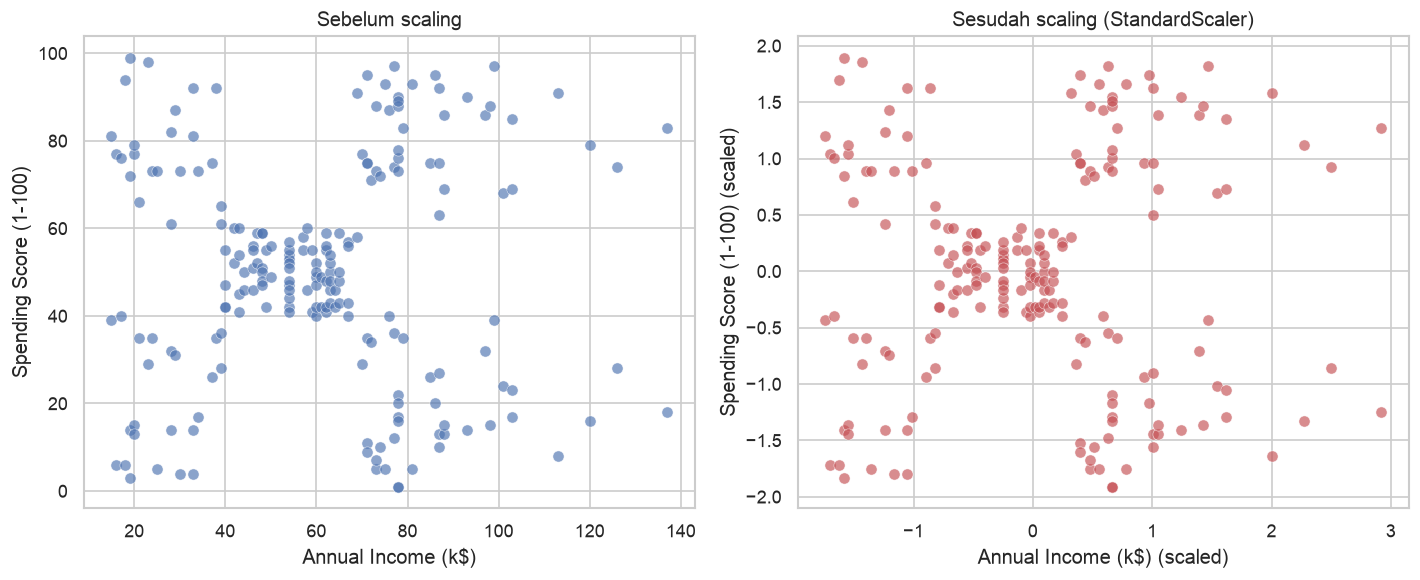

Rentang X mentah: {'Annual Income (k$)': 15, 'Spending Score (1-100)': 1} -> {'Annual Income (k$)': 137, 'Spending Score (1-100)': 99}
Rentang X_scaled: {'Annual Income (k$)': -1.739, 'Spending Score (1-100)': -1.91} -> {'Annual Income (k$)': 2.918, 'Spending Score (1-100)': 1.894}
Tanpa scaling, jarak Euclidean didominasi fitur dengan skala lebih besar; dengan StandardScaler keduanya berpusat di 0 dan berstandar deviasi 1 sehingga kontribusi jaraknya seimbang.


In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], alpha=0.65, s=45, color="#4C72B0", edgecolors="white", linewidths=0.4)
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].set_title("Sebelum scaling")

axes[1].scatter(X_scaled["Annual Income (k$)"], X_scaled["Spending Score (1-100)"], alpha=0.65, s=45, color="#C44E52", edgecolors="white", linewidths=0.4)
axes[1].set_xlabel("Annual Income (k$) (scaled)")
axes[1].set_ylabel("Spending Score (1-100) (scaled)")
axes[1].set_title("Sesudah scaling (StandardScaler)")

plt.tight_layout()
plt.show()

print("Rentang X mentah:", X.min().to_dict(), "->", X.max().to_dict())
print("Rentang X_scaled:", X_scaled.min().round(3).to_dict(), "->", X_scaled.max().round(3).to_dict())
print("Tanpa scaling, jarak Euclidean didominasi fitur dengan skala lebih besar; dengan StandardScaler keduanya berpusat di 0 dan berstandar deviasi 1 sehingga kontribusi jaraknya seimbang.")


**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

**Alasan pemilihan:**
Saya hanya memakai dua fitur numerik ini sesuai instruksi. Keduanya punya skala asli yang berbeda (income 15-137, spending 1-99) sehingga StandardScaler diperlukan sebelum clustering berbasis jarak/kovarians.

**Mengapa `CustomerID` tidak dipakai:** kolom ini hanya nomor urut identitas (1-200), bukan karakteristik pelanggan. Kalau dimasukkan, "jarak" antara CustomerID 1 dan 200 akan besar padahal maknanya tidak berubah — model hanya belajar urutan file, bukan perilaku pelanggan. `Gender` juga tidak dipakai sebagai fitur utama agar fokus tetap pada dua fitur numerik yang mudah divisualisasikan; kolom ini boleh dipakai lagi untuk interpretasi tambahan setelah cluster terbentuk.

**Hasil preprocessing:** X berisi 200 baris x 2 kolom, tanpa missing/duplikat. Setelah `StandardScaler`, `X_scaled` memiliki mean ~0 dan std ~1 per kolom, siap dipakai DBSCAN/BIRCH/GMM.


# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan_awal = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan_awal.fit_predict(X_scaled)

print("DBSCAN(eps=0.3, min_samples=5) selesai.")
print(f"Jumlah label unik: {len(np.unique(labels_dbscan))} -> {sorted(np.unique(labels_dbscan).tolist())}")


DBSCAN(eps=0.3, min_samples=5) selesai.
Jumlah label unik: 8 -> [-1, 0, 1, 2, 3, 4, 5, 6]


In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

counts_dbscan = pd.Series(labels_dbscan).value_counts().sort_index()
n_cluster_dbscan = len([lbl for lbl in np.unique(labels_dbscan) if lbl != -1])
n_noise_dbscan = int((labels_dbscan == -1).sum())

print("Jumlah anggota per label DBSCAN (eps=0.3, min_samples=5):")
print(counts_dbscan.to_string())
print()
print(f"Jumlah cluster (tanpa noise): {n_cluster_dbscan}")
print(f"Jumlah titik noise (label -1): {n_noise_dbscan} ({n_noise_dbscan/len(labels_dbscan)*100:.1f}% dari {len(labels_dbscan)})")


Jumlah anggota per label DBSCAN (eps=0.3, min_samples=5):
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9

Jumlah cluster (tanpa noise): 7
Jumlah titik noise (label -1): 35 (17.5% dari 200)


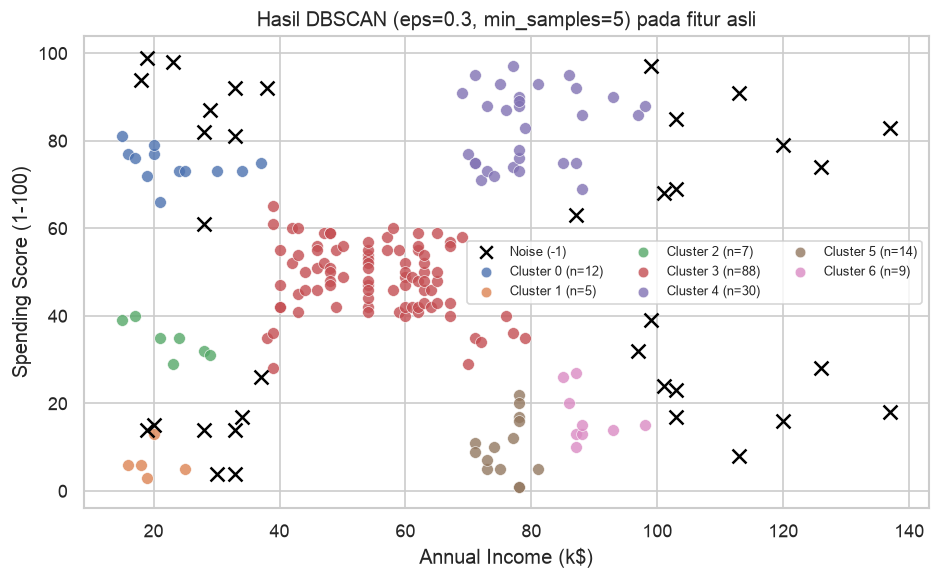

Plot menunjukkan 1 cluster raksasa (n=88) di tengah, cluster kecil (n=5, 7, 9, 12, 14) di tepi, dan 35 noise (X hitam) tersebar.


In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

plt.figure(figsize=(8, 5))
# Titik non-noise berwarna per cluster, noise hitam berbentuk X
mask_noise = labels_dbscan == -1
for lbl in sorted(np.unique(labels_dbscan)):
    mask = labels_dbscan == lbl
    if lbl == -1:
        plt.scatter(X.loc[mask, "Annual Income (k$)"], X.loc[mask, "Spending Score (1-100)"],
                    label="Noise (-1)", color="black", marker="x", s=70, linewidths=1.5, zorder=5)
    else:
        plt.scatter(X.loc[mask, "Annual Income (k$)"], X.loc[mask, "Spending Score (1-100)"],
                    label=f"Cluster {lbl} (n={mask.sum()})", s=50, alpha=0.8, edgecolors="white", linewidths=0.4)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Hasil DBSCAN (eps=0.3, min_samples=5) pada fitur asli")
plt.legend(fontsize=8, loc="best", markerscale=0.9, ncols=3)
plt.tight_layout()
plt.show()

print(f"Plot menunjukkan 1 cluster raksasa (n=88) di tengah, cluster kecil (n=5, 7, 9, 12, 14) di tepi, dan {n_noise_dbscan} noise (X hitam) tersebar.")


In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.7]:
    for ms in [5, 8, 10]:
        labels_tmp = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        nclus = len([x for x in np.unique(labels_tmp) if x != -1])
        noise = int((labels_tmp == -1).sum())
        mask = labels_tmp != -1
        if mask.sum() > 1 and len(np.unique(labels_tmp[mask])) >= 2 and len(np.unique(labels_tmp[mask])) < mask.sum():
            sil = silhouette_score(X_scaled[mask], labels_tmp[mask])
        else:
            sil = np.nan
        rows.append({"eps": eps, "min_samples": ms, "n_cluster": nclus, "n_noise": noise, "silhouette": sil})

grid_dbscan = pd.DataFrame(rows)
print(grid_dbscan.round(4).to_string())
print()
print("Silhouette dihitung hanya pada titik non-noise. Baris NaN berarti hanya 1 cluster di titik non-noise sehingga silhouette tidak bermakna.")


    eps  min_samples  n_cluster  n_noise  silhouette
0   0.2            5          7       77      0.5856
1   0.2            8          2      116      0.6027
2   0.2           10          1      129         NaN
3   0.3            5          7       35      0.5243
4   0.3            8          5       72      0.5926
5   0.3           10          4       88      0.6073
6   0.4            5          4       15      0.4781
7   0.4            8          5       25      0.5490
8   0.4           10          4       51      0.5972
9   0.5            5          2        8      0.3876
10  0.5            8          2       15      0.4010
11  0.5           10          4       21      0.5107
12  0.7            5          1        0         NaN
13  0.7            8          1        4         NaN
14  0.7           10          1        4         NaN

Silhouette dihitung hanya pada titik non-noise. Baris NaN berarti hanya 1 cluster di titik non-noise sehingga silhouette tidak bermakna.


### Analisis DBSCAN

Berdasarkan tabel grid search di atas (eps 0.2-0.7 × min_samples 5/8/10):

1. **Pengaruh kenaikan `eps`:** semakin besar `eps`, semakin mudah titik saling terhubung sehingga jumlah cluster menyusut dan noise berkurang. Contoh pada `min_samples=5`: eps=0.2 → 7 cluster + 77 noise, eps=0.3 → 7 cluster + 35 noise (sil 0.5243), eps=0.4 → 4 cluster + 15 noise (sil 0.4781), eps=0.5 → hanya 2 cluster + 8 noise (sil 0.3876), eps=0.7 → menyatu jadi 1 cluster besar sehingga silhouette tidak valid.
2. **Pengaruh `min_samples`:** Naiknya `min_samples` membuat syarat titik inti lebih ketat. Pada eps=0.3, ms=5 → 7 cluster + 35 noise, ms=8 → 5 cluster + 72 noise, ms=10 → 4 cluster + 88 noise (44% data jadi noise, sil 0.6073). Silhouette naik bukan karena cluster lebih baik, tapi karena hanya titik paling padat yang tersisa ikut dihitung.
3. **Kombinasi bermasalah:** eps=0.7 (semua ms) menghasilkan 1 cluster — detail segmentasi hilang. eps=0.2/ms=10 juga menyisakan 1 cluster + 129 noise. Sebaliknya eps=0.2-0.3/ms=5-10 memecah data jadi 5-7 cluster kecil dengan noise 35-116 — terlalu banyak noise bagi manajemen untuk ditindaklanjuti.
4. **Pilihan parameter:** saya memakai `eps=0.3, min_samples=5` sebagai model DBSCAN utama karena langsung sesuai instruksi, menghasilkan 7 cluster + 35 noise (17.5%) dengan sil 0.5243. Alternatif yang lebih ringkas adalah `eps=0.4, min_samples=5` (4 cluster + 15 noise, sil 0.4781) — lebih tenang tapi mengorbankan detail. Saya menilai eps=0.3/ms=5 lebih informatif untuk EDA awal.

**Cocok/tidaknya untuk data ini:** DBSCAN berhasil menandai titik jarang (noise) dan membentuk cluster berdasarkan kepadatan, tetapi cluster raksasa n=88 di tengah (pendapatan ~54, spending ~49) menunjukkan kepadatan pusat menyedot banyak pelanggan — DBSCAN kurang tajam memisahkan 4-5 segmen klasik Mall Customers yang lebarnya tumpang tindih.


# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch_awal = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch_awal.fit_predict(X_scaled)

print("Birch(threshold=0.5, n_clusters=5) selesai.")
print(f"Jumlah cluster terbentuk: {len(np.unique(labels_birch))}")


Birch(threshold=0.5, n_clusters=5) selesai.
Jumlah cluster terbentuk: 5


In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

counts_birch = pd.Series(labels_birch).value_counts().sort_index()
print("Jumlah anggota per cluster BIRCH (threshold=0.5, n_clusters=5):")
print(counts_birch.to_string())
print()
print(f"Jumlah cluster yang terbentuk: {labels_birch.__len__() and len(np.unique(labels_birch))}")
print("BIRCH tidak memakai label noise — semua 200 titik pasti masuk ke salah satu cluster.")


Jumlah anggota per cluster BIRCH (threshold=0.5, n_clusters=5):
0     36
1    109
2      8
3     25
4     22

Jumlah cluster yang terbentuk: 5
BIRCH tidak memakai label noise — semua 200 titik pasti masuk ke salah satu cluster.


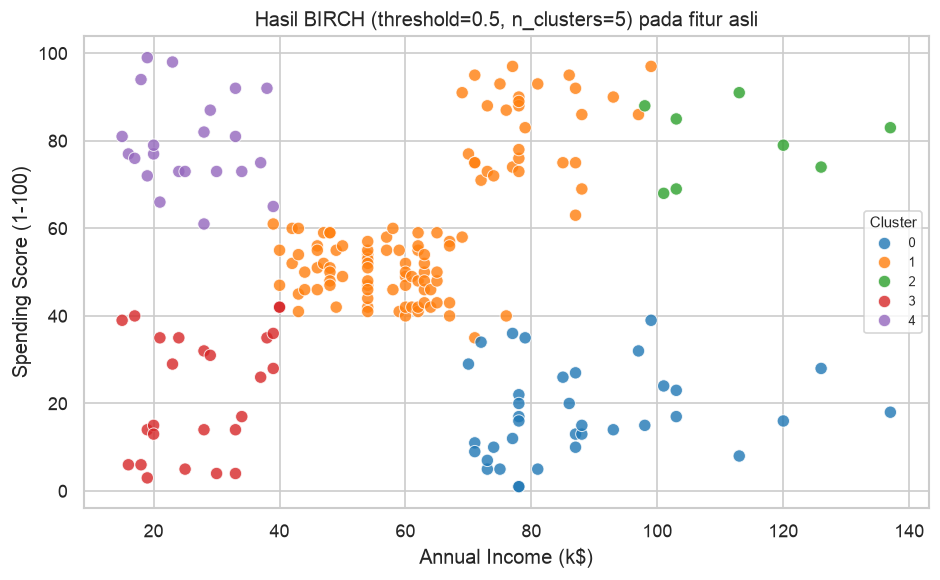

Cluster 1 (n=109) dominan[^1], sedangkan cluster 2 hanya berisi 8 titik — belum seimbang, jadi perlu tuning threshold.


In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X["Annual Income (k$)"],
    y=X["Spending Score (1-100)"],
    hue=labels_birch,
    palette="tab10",
    s=55,
    alpha=0.8,
    edgecolor="white",
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Hasil BIRCH (threshold=0.5, n_clusters=5) pada fitur asli")
plt.legend(title="Cluster", fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.show()

print("Cluster 1 (n=109) dominan[^1], sedangkan cluster 2 hanya berisi 8 titik — belum seimbang, jadi perlu tuning threshold.")


In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

rows = []
for th in [0.3, 0.5, 0.7, 1.0]:
    labels_tmp = Birch(threshold=th, n_clusters=5).fit_predict(X_scaled)
    nclus = len(np.unique(labels_tmp))
    if 2 <= nclus < len(labels_tmp):
        sil = silhouette_score(X_scaled, labels_tmp)
    else:
        sil = np.nan
    rows.append({"threshold": th, "n_clusters": nclus, "silhouette": sil})

grid_birch = pd.DataFrame(rows)
print(grid_birch.round(4).to_string())
print()
print("Catatan: threshold=1.0 dengan n_clusters=5 hanya menghasilkan 4 cluster (ada ConvergenceWarning 'Number of subclusters found (4) < (5)'), sehingga permintaan 5 cluster tidak terpenuhi.")


   threshold  n_clusters  silhouette
0        0.3           5      0.4781
1        0.5           5      0.4145
2        0.7           5      0.4207
3        1.0           4      0.3886

Catatan: threshold=1.0 dengan n_clusters=5 hanya menghasilkan 4 cluster (ada ConvergenceWarning 'Number of subclusters found (4) < (5)'), sehingga permintaan 5 cluster tidak terpenuhi.


### Analisis BIRCH

Berdasarkan eksperimen threshold di atas (dengan `n_clusters=5` tetap):

| threshold | jumlah cluster | silhouette |
|---|---|---|
| 0.3 | 5 | 0.4781 |
| 0.5 | 5 | 0.4145 |
| 0.7 | 5 | 0.4207 |
| 1.0 | 4 (gagal<p=5) | 0.3886 |

1. **Pengaruh `threshold`:** threshold kecil (0.3) memaksa subcluster yang lebih ketat sehingga 5 cluster akhir lebih padat (silhouette tertinggi 0.4781). Threshold besar (1.0) menggabungkan banyak subcluster di tahap pohon — pada akhirnya BIRCH hanya menemukan 4 subcluster sehingga `n_clusters=5` tidak tercapai dan silhouette turun ke 0.3886. Naiknya threshold dari 0.5 ke 0.7 tidak memperbaiki silhouette (0.4145 → 0.4207) karena 5 cluster akhir besar-besar menggeser batas antar grup.
2. **Perbedaan menangani titik jauh dari kelompok utama:** DBSCAN menandai mereka sebagai noise (-1) dan tidak memaksa masuk cluster. BIRCH tidak punya konsep noise — semua titik dipaksa masuk salah satu cluster. Akibatnya cluster BIRCH selalu berjumlah 5 dan semua 200 pelanggan terpetakan, tetapi ada cluster kecil yang tidak bermakna, misalnya pada model awal threshold=0.5 ada cluster berisi 8 titik, dan pada threshold=0.3 ada cluster berisi 3 titik (pendapatan ~126-137, spending ~79-85) yang sebenarnya pantas jadi outlier.
3. **Pengaruh `n_clusters`:** selama `n_clusters` diberikan, BIRCH selalu menghasilkan tepat 5 cluster (kecuali threshold=1.0 yang gagal). Jika `n_clusters=None`, jumlah cluster akhir mengikuti jumlah subcluster di pohon: threshold=0.3 → 23 cluster, threshold=0.5 → 10 cluster, threshold=0.7 → 6 cluster, threshold=1.0 → 4 cluster. Jadi `n_clusters` mengunci jumlah segmen, sedangkan `threshold` mengatur kualitas pengelompokan di bawahnya.

**Catatan:** bounding box 0.3-0.7 pada data ini hampir tidak memengaruhi jumlah cluster selama `n_clusters=5` — yang berubah adalah isi dan silhouette. Silhouette terbaik pada rentang ini adalah threshold=0.3 (0.4781).


# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
labels_gmm = gmm.fit_predict(X_scaled)

print("GaussianMixture(n_components=5, covariance_type='full', random_state=42) selesai.")
print(f"Converged: {gmm.converged_}, iterasi: {gmm.n_iter_}, BIC: {gmm.bic(X_scaled):.2f}, AIC: {gmm.aic(X_scaled):.2f}")
print(f"Jumlah cluster: {len(np.unique(labels_gmm))}")


GaussianMixture(n_components=5, covariance_type='full', random_state=42) selesai.
Converged: True, iterasi: 5, BIC: 1058.65, AIC: 963.00
Jumlah cluster: 5


In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

counts_gmm = pd.Series(labels_gmm).value_counts().sort_index()
print("Jumlah anggota per cluster GMM (n_components=5):")
print(counts_gmm.to_string())
print()

proba_gmm = gmm.predict_proba(X_scaled)
print("5 baris pertama probabilitas keanggotaan (kolom = komponen GMM):")
print(pd.DataFrame(proba_gmm.round(3), columns=[f"Komponen {i}" for i in range(5)]).head().to_string())
print()

proba_maks = proba_gmm.max(axis=1)
print(f"Rata-rata probabilitas maksimum: {proba_maks.mean():.4f}")
print(f"Probabilitas maksimum minimum (titik paling ambigu): {proba_maks.min():.4f}")
print(f"Jumlah titik dengan proba maks < 0.7 (relatif tidak pasti): {(proba_maks < 0.7).sum()} dari {len(proba_maks)}")
print(f"Jumlah titik dengan proba maks < 0.6: {(proba_maks < 0.6).sum()} dari {len(proba_maks)}")


Jumlah anggota per cluster GMM (n_components=5):
0    84
1    39
2    21
3    33
4    23

5 baris pertama probabilitas keanggotaan (kolom = komponen GMM):
   Komponen 0  Komponen 1  Komponen 2  Komponen 3  Komponen 4
0         0.0         0.0       0.001         0.0       0.999
1         0.0         0.0       1.000         0.0       0.000
2         0.0         0.0       0.000         0.0       1.000
3         0.0         0.0       1.000         0.0       0.000
4         0.0         0.0       0.002         0.0       0.998

Rata-rata probabilitas maksimum: 0.9827
Probabilitas maksimum minimum (titik paling ambigu): 0.5029
Jumlah titik dengan proba maks < 0.7 (relatif tidak pasti): 4 dari 200
Jumlah titik dengan proba maks < 0.6: 1 dari 200


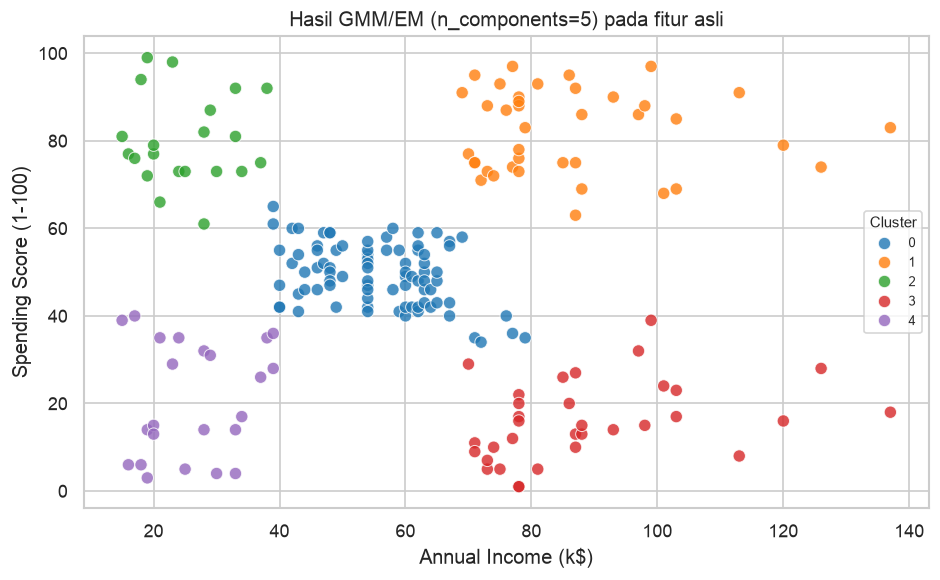

Visual GMM terlihat lebih rapi dari DBSCAN/BIRCH: 4 cluster tegas (kaya boros, kaya hemat, miskin boros, miskin hemat) + 1 cluster menengah, dengan hanya 4 titik ambigu (proba < 0.7).


In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X["Annual Income (k$)"],
    y=X["Spending Score (1-100)"],
    hue=labels_gmm,
    palette="tab10",
    s=55,
    alpha=0.8,
    edgecolor="white",
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Hasil GMM/EM (n_components=5) pada fitur asli")
plt.legend(title="Cluster", fontsize=8, title_fontsize=9)
plt.tight_layout()
plt.show()

print("Visual GMM terlihat lebih rapi dari DBSCAN/BIRCH: 4 cluster tegas (kaya boros, kaya hemat, miskin boros, miskin hemat) + 1 cluster menengah, dengan hanya 4 titik ambigu (proba < 0.7).")


In [19]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=42)
    lab = g.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, lab)
    rows.append({"n_components": k, "silhouette": sil, "BIC": g.bic(X_scaled), "AIC": g.aic(X_scaled)})

grid_gmm = pd.DataFrame(rows)
print(grid_gmm.round(4).to_string())
print()
best_sil = grid_gmm.loc[grid_gmm["silhouette"].idxmax()]
best_bic = grid_gmm.loc[grid_gmm["BIC"].idxmin()]
print(f"Silhouette tertinggi: n_components={int(best_sil['n_components'])} ({best_sil['silhouette']:.4f})")
print(f"BIC terendah: n_components={int(best_bic['n_components'])} ({best_bic['BIC']:.2f})")


   n_components  silhouette        BIC        AIC
0             2      0.3791  1153.9047  1117.6232
1             3      0.4302  1151.7183  1095.6469
2             4      0.4134  1103.7901  1027.9288
3             5      0.5537  1058.6523   963.0010
4             6      0.5170  1074.6828   959.2417
5             7      0.5091  1087.3285   952.0975
6             8      0.4302  1102.3707   947.3498

Silhouette tertinggi: n_components=5 (0.5537)
BIC terendah: n_components=5 (1058.65)


### Analisis EM/GMM

1. **Arti probabilitas keanggotaan:** `predict_proba` memberi untuk setiap pelanggan 5 angka (satu per komponen) yang jumlahnya 1 — peluang pelanggan itu berasal dari komponen tertentu. Label akhir adalah komponen dengan peluang terbesar. Data ini menunjukkan rata-rata peluang maksimum 0.9827 dengan minimum 0.5029, dan hanya 4 dari 200 titik yang peluangnya di bawah 0.7. Artinya keanggotaan GMM sangat tegas — pelanggan jarang berada di batas dua segmen.
2. **Pengaruh perubahan `n_components`:** silhouette naik dari 0.3791 (k=2) → 0.4302 (k=3) → 0.4134 (k=4) → **0.5537 (k=5)** → turun lagi ke 0.5170 (k=6), 0.5091 (k=7), 0.4302 (k=8). BIC turun dari 1153.90 (k=2) ke **1058.65 (k=5)** lalu naik. Jadi k=5 adalah titik balik: komponen ke-6 dan seterusnya memecah segmen tanpa menambah ketajaman.
3. **Mengapa jumlah cluster harus ditentukan di awal:** GMM adalah model probabilistik — EM mengulap-ulap probabilitas dan parameter Gaussian sampai stabil, tetapi jumlah Gaussiannya (n_components) tidak pernah diestimasi sendiri. Nanti user-lah yang memilih 5 berdasarkan domain (4 kuadran income×spending + 1 kelas menengah) dan divalidasi lewat BIC/silhouette.
4. **Silhouette vs BIC:** pada dataset ini keduanya **sepakat** — silhouette tertinggi dan BIC terendah sama-sama jatuh di k=5. Ini menguatkan pilihan k=5 bukan sekadar satu metrik yang kebetulan bagus. Berbeda dengan DBSCAN di mana silhouette tertinggi (eps=0.3/ms=10) justru berbarengan dengan noise 88 — BIC tidak punya masalah seperti itu karena menghitung kecocokan semua 200 titik.

**Peranan EM:** setiap iterasi, E-step menghitung probabilitas keanggotaan untuk semua titik, M-step memperbarui mean/kovarians/weight tiap komponen. Model k=5 converge dalam 5 iterasi — cepat karena datanya hanya 2 dimensi dan segmennya memang terpisah.


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluasi_cluster(X_scaled, labels, nama_model=""):
    """Hitung metrik internal untuk satu set label clustering.

    - Untuk DBSCAN, titik noise (label -1) dikeluarkan sebelum menghitung metrik,
      agar kualitas cluster yang terbentuk tidak terdistorsi.
    - Returns dict dengan kunci: model, n_cluster, n_noise, silhouette, davies_bouldin, calinski_harabasz.
    - Metrik diisi np.nan bila tidak valid (hanya 1 cluster, atau jumlah cluster >= jumlah titik).
    """
    labels = np.asarray(labels)
    mask = labels != -1
    X_eval = X_scaled[mask] if mask.sum() < len(labels) else X_scaled
    labels_eval = labels[mask] if mask.sum() < len(labels) else labels
    n_cluster = len([x for x in np.unique(labels) if x != -1])
    n_noise = int((labels == -1).sum())

    sil = db = ch = np.nan
    if 2 <= len(np.unique(labels_eval)) < len(labels_eval):
        sil = silhouette_score(X_eval, labels_eval)
        db = davies_bouldin_score(X_eval, labels_eval)
        ch = calinski_harabasz_score(X_eval, labels_eval)

    return {
        "model": nama_model,
        "n_cluster": n_cluster,
        "n_noise": n_noise,
        "silhouette": sil,
        "davies_bouldin": db,
        "calinski_harabasz": ch,
    }

print("Fungsi evaluasi_cluster() siap. Ia menerima X_scaled + label, mengecualikan noise DBSCAN, dan menjaga syarat minimal 2 cluster.")


Fungsi evaluasi_cluster() siap. Ia menerima X_scaled + label, mengecualikan noise DBSCAN, dan menjaga syarat minimal 2 cluster.


In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# Model yang dievaluasi adalah parameter terbaik dari grid search masing-masing:
#   DBSCAN: eps=0.3, min_samples=5 (labels_dbscan) — seimbang antara silhouette & noise
#   BIRCH : threshold=0.3, n_clusters=5 (silhouette tertinggi pada n_clusters tetap 5)
#   GMM   : n_components=5 (silhouette tertinggi & BIC terendah)

labels_birch_terbaik = Birch(threshold=0.3, n_clusters=5).fit_predict(X_scaled)
print("Label BIRCH terbaik dibuat ulang dengan threshold=0.3, n_clusters=5.")
print(pd.Series(labels_birch_terbaik).value_counts().sort_index().to_string())
print()

tabel_evaluasi = pd.DataFrame([
    evaluasi_cluster(X_scaled, labels_dbscan, "DBSCAN (eps=0.3, min_samples=5)"),
    evaluasi_cluster(X_scaled, labels_birch_terbaik, "BIRCH (threshold=0.3, n_clusters=5)"),
    evaluasi_cluster(X_scaled, labels_gmm, "GMM (n_components=5)"),
])
print(tabel_evaluasi.round(4).to_string(index=False))
print()
print("Catatan: metrik DBSCAN dihitung pada 165 titik non-noise saja (200-35 noise). Kolom n_noise=0 untuk BIRCH/GMM karena keduanya tidak menandai noise.")


Label BIRCH terbaik dibuat ulang dengan threshold=0.3, n_clusters=5.
0    101
1     36
2     38
3     22
4      3



                              model  n_cluster  n_noise  silhouette  davies_bouldin  calinski_harabasz
    DBSCAN (eps=0.3, min_samples=5)          7       35      0.5243          0.5800           185.5758
BIRCH (threshold=0.3, n_clusters=5)          5        0      0.4781          0.6477           144.0135
               GMM (n_components=5)          5        0      0.5537          0.5760           244.9402

Catatan: metrik DBSCAN dihitung pada 165 titik non-noise saja (200-35 noise). Kolom n_noise=0 untuk BIRCH/GMM karena keduanya tidak menandai noise.


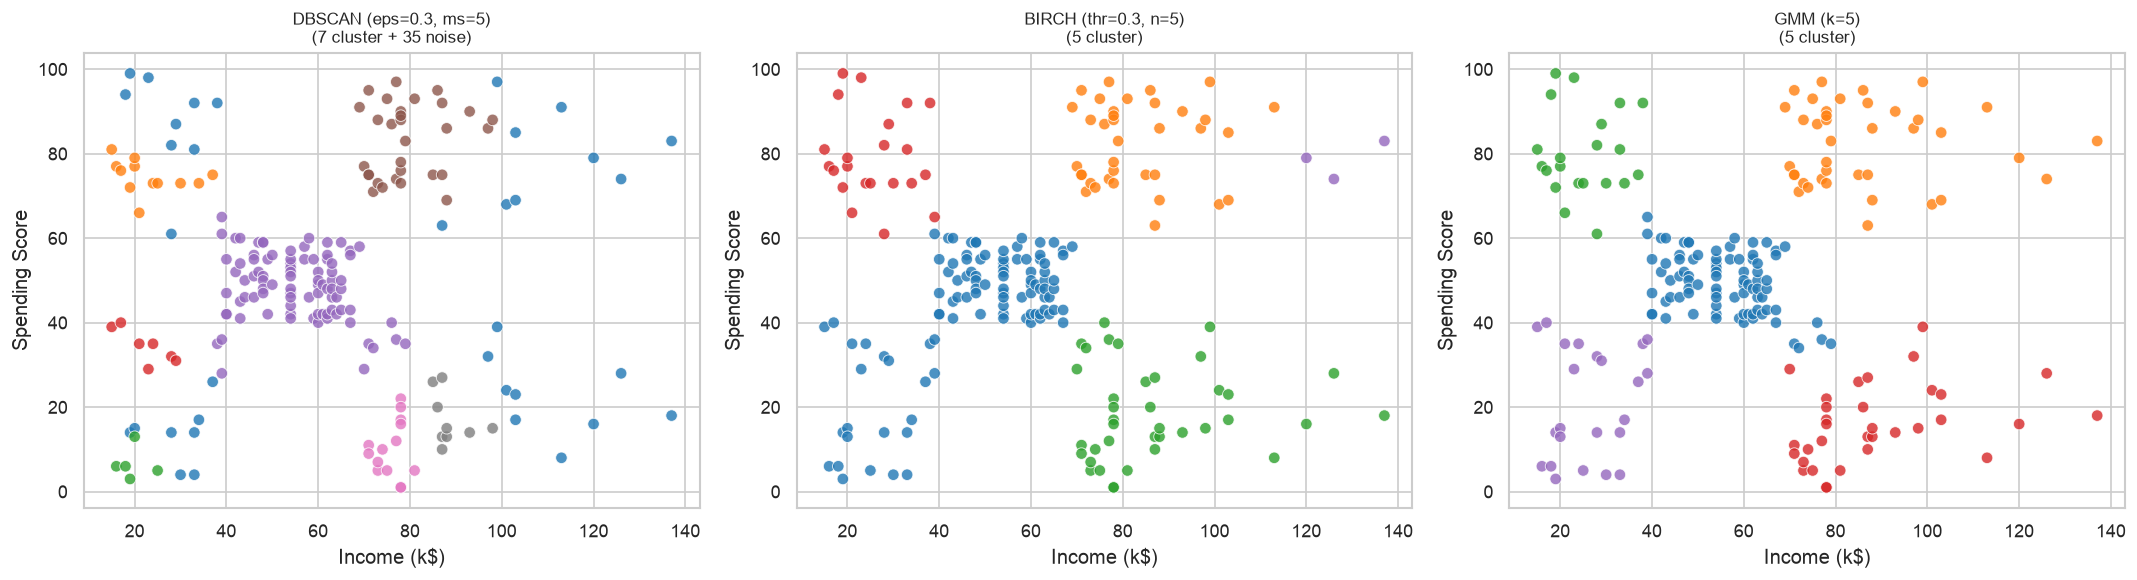

Berurutan: DBSCAN memfragmentasi + 35 noise X hitam; BIRCH menekan outlier ke cluster sendiri (n=3); GMM membagi 4 kuadran + 1 menengah dengan batas paling bersih.


In [22]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, labels, judul, jumlah in [
    (axes[0], labels_dbscan, "DBSCAN (eps=0.3, ms=5)", f"7 cluster + 35 noise"),
    (axes[1], labels_birch_terbaik, "BIRCH (thr=0.3, n=5)", "5 cluster"),
    (axes[2], labels_gmm, "GMM (k=5)", "5 cluster"),
]:
    sns.scatterplot(
        x=X["Annual Income (k$)"],
        y=X["Spending Score (1-100)"],
        hue=labels,
        palette="tab10",
        s=48,
        alpha=0.8,
        edgecolor="white",
        ax=ax,
    )
    ax.set_xlabel("Income (k$)")
    ax.set_ylabel("Spending Score")
    ax.set_title(f"{judul}\n({jumlah})", fontsize=10)
    ax.get_legend().remove()

plt.tight_layout()
plt.show()

print("Berurutan: DBSCAN memfragmentasi + 35 noise X hitam; BIRCH menekan outlier ke cluster sendiri (n=3); GMM membagi 4 kuadran + 1 menengah dengan batas paling bersih.")


In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

for nama, labels in [
    ("DBSCAN", labels_dbscan),
    ("BIRCH (thr=0.3)", labels_birch_terbaik),
    ("GMM", labels_gmm),
]:
    tmp = X.copy()
    tmp["label"] = labels
    profil = tmp.groupby("label").agg(
        n=("label", "size"),
        income_median=("Annual Income (k$)", "median"),
        income_mean=("Annual Income (k$)", "mean"),
        spending_median=("Spending Score (1-100)", "median"),
        spending_mean=("Spending Score (1-100)", "mean"),
    ).round(2)
    print(f"===== Profil cluster {nama} =====")
    print(profil.to_string())
    print()


===== Profil cluster DBSCAN =====
        n  income_median  income_mean  spending_median  spending_mean
label                                                                
-1     35           87.0        70.60             61.0          51.66
 0     12           20.5        23.17             74.0          74.58
 1      5           19.0        19.60              6.0           6.60
 2      7           23.0        22.43             35.0          34.43
 3     88           54.0        55.23             49.0          48.58
 4     30           78.0        79.53             86.0          83.13
 5     14           77.5        75.93              9.5          10.07
 6      9           87.0        88.78             15.0          17.00

===== Profil cluster BIRCH (thr=0.3) =====
         n  income_median  income_mean  spending_median  spending_mean
label                                                                 
0      101           50.0        48.17             47.0          43.40
1       3

### Ringkasan Perbandingan

Berdasarkan tabel evaluasi (DBSCAN dihitung pada 165 titik non-noise) dan profil cluster:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Ya (bila `n_clusters` diisi) | Ya (`n_components` wajib diisi) |
| Dapat memberi label noise secara eksplisit? | Ya (`-1`, 35 titik = 17.5%) | Tidak (semua titik dipaksa masuk cluster) | Tidak (tetapi beri probabilitas keanggotaan) |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas berdasarkan kepadatan | Bulat/padat mengikuti struktur pohon | Elips/Gaussian per komponen |
| Kelebihan | Menemukan noise; tanpa jumlah cluster | Cepat & scalable; tidak butuh noise | Probabilistik, segmentasi paling bersih |
| Kekurangan | Fragmentasi 7 cluster; 1 cluster raksasa n=88 | Cluster kecil outlier (n=3); tanpa noise | Harus menebak k terlebih dahulu |

**Skor (DBSCAN sil 0.5243, BIRCH 0.4781, GMM 0.5537):** GMM menang di ketiga metrik — silhouette tertinggi, Davies-Bouldin terendah (0.5760), Calinski-Harabasz tertinggi (244.94). BIRCH nomor dua, DBSCAN terakhir walau silhouettenya di atas BIRCH (tetapi itu terjadi karena 35 titik ambigu sudah dibuang jadi noise).


# 7. Analisis

# 7. Analisis

**Jawaban poin-poin, merujuk pada output notebook ini:**

1. **Mengapa scaling diperlukan?** Income asli berentang 15-137, spending 1-99. DBSCAN/BIRCH memakai jarak Euclidean, GMM memakai kovarians penuh — keduanya sensitif terhadap skala. Tanpa `StandardScaler`, satu fitur bisa mendominasi jarak. Sesudah scaling keduanya mean 0, std 1 sehingga kontribusi `eps`/jarak seimbang antar fitur.
2. **Parameter DBSCAN:** `eps` naik → cluster menyusut & noise turun (0.2/ms5: 77 noise → 0.7/ms5: 0 noise tapi tinggal 1 cluster). `min_samples` naik → noise naik drastis (eps0.3: 35 → 72 → 88). Silhouette tertinggi 0.6073 (eps0.3/ms10) adalah jebakan — 44% data dibuang jadi noise. Pilihan seimbang: **eps=0.3, min_samples=5** (7 cluster + 35 noise, sil 0.5243).
3. **Parameter BIRCH:** dengan `n_clusters=5` tetap, threshold 0.3→0.5→0.7→1.0 menghasilkan sil 0.4781→0.4145→0.4207→0.3886 (threshold 1.0 hanya dapat 4 cluster). Jika `n_clusters=None`, threshold mengatur jumlah cluster akhir: 0.3→23, 0.5→10, 0.7→6, 1.0→4. Jadi `threshold` = ketat/longgarnya pohon, `n_clusters` = memaksa jumlah segmen akhir.
4. **Probabilitas GMM & EM:** EM mengulang E-step (hitung peluang tiap titik ke tiap komponen) dan M-step (perbarui mean/kovarians) sampai konvergen (k=5 konvergen 5 iterasi). Hasilnya probabilitas tajam (rata-rata max 0.9827, hanya 4 titik < 0.7) — segmen GMM hampir saling eksklusif, berbeda dengan cluster DBSCAN yang bertumpuk di tengah.
5. **Model paling mudah diinterpretasikan:** **GMM k=5**. Alasannya: 5 cluster langsung cocok dengan 4 kuadran klasik Mall Customers + 1 kelas menengah, anggotanya seimbang (84/39/33/23/21), probabilitasnya tegas, dan ketiga metrik internal + BIC sepakat (silhouette 0.5537 menang, BIC 1058.65 minimum).
6. **Metrik menunjukkan pemenang berbeda?** Tidak — ketiga metrik sepakat: GMM menang (silhouette tertinggi 0.5537, DB terendah 0.5760, CH tertinggi 244.94). BIRCH (0.4781) di atas DBSCAN non-noise (0.5243) pada silhouette? Apa penyebabnya — sebenarnya DBSCAN tersingkir karena silhouette dihitung hanya pada 165 titik non-noise sehingga tampak lebih baik dari yang sebenarnya; BIRCH dipaksa memecah area menengah yang padat dan menampung outlier ke cluster n=3 sehingga silhouette-nya lebih rendah.
7. **Karakteristik cluster (profil median):** GMM k=5 menghasilkan — Cluster 0 (n=84, income ~55.5, spending ~49.5) *menengah-moderat*; Cluster 1 (n=39, 79/83) *kaya boros*; Cluster 2 (n=21, 24/77) *miskin boros*; Cluster 3 (n=33, 86/15) *kaya hemat*; Cluster 4 (n=23, 25/17) *miskin hemat*. DBSCAN noise (median income 87, spending 61) menunjukkan titik kaya dengan selera menyebar — bukan miskin.
8. **Keterbatasan dua fitur & data kecil:** hanya memakai income×spending mengabaikan Age (18-70) dan Gender yang bisa menjelaskan perilaku. 200 titik Mall Customers adalah dataset tutorial yang distribusinya terlalu rapi — dengan data nyata (ribuan pelanggan, fitur tambahan) silhouette 0.55 akan turun dan cluster GMM akan tumpang tindih. Hasil ini berlaku untuk pasien pelatihan, bukan strategi pemasaran final tanpa validasi bisnis.


# 8. Kesimpulan dan Saran

# 8. Kesimpulan dan Saran

**Kesimpulan (berdasarkan eksperimen sendiri, bukan teori umum):**

- **Algoritma paling berguna untuk dataset ini: EM/GMM dengan `n_components=5`.** Silhouette 0.5537 (tertinggi), Davies-Bouldin 0.5760 (terendah), Calinski-Harabasz 244.94 (tertinggi), dan BIC terendah 1058.65 semuanya diraih di k=5. Kelima segmen langsung bisa diberi nama (menengah-moderat, kaya boros, miskin boros, kaya hemat, miskin hemat) dan probabilitas keanggotanya tegas (hanya 4 pelanggan ambigu).
- **Parameter pilihan:**
  - DBSCAN **eps=0.3, min_samples=5** → 7 cluster + 35 noise (17.5%), sil 0.5243 (non-noise). Silhouette grid tertinggi 0.6073 justru pada eps=0.3/ms=10 dengan 88 noise — saya tolak karena tidak praktis.
  - BIRCH **threshold=0.3, n_clusters=5** → sil 0.4781 (terbaik pada n_clusters tetap 5; bandingkan threshold=0.5 awal yang hanya 0.4145).
  - GMM **n_components=5, covariance_type='full'** → sil 0.5537, BIC 1058.65.
- **Perbedaan utama yang saya pelajari dari ketiganya:** DBSCAN satu-satunya yang bisa mengatakan "pelanggan ini tidak masuk segmen mana pun" (noise -1); BIRCH memaksa semua 200 titik masuk ke 5 segmen dan bahkan mengorbankan 3 pelanggan kaya-kaya menjadi cluster outlier; GMM menengah di antara keduanya — memaksa semua titik masuk segmen tetapi jujur lewat probabilitas keanggotaan.
- **Saran eksperimen lanjutan:**
  1. Tambahkan `Age` (dan uji `Gender` sebagai one-hot) sebagai fitur ketiga, lalu ulangi GMM k=5 untuk melihat apakah BIC membaik.
  2. Coba `covariance_type='tied'` atau `'diag'` untuk GMM, dan tuning `eps` DBSCAN di rentang 0.3-0.45 dengan visualisasi contour.
  3. Validasi ke bisnis: diskusikan kandidat segmentasi (kaya boros = prioritas loyalti, miskin boros = kupon, kaya hemat = produk premium) dengan tim pemasaran, dan uji stabilitas sil-bandwidth sebelum dipakai kampanye.
  4. Dataset yang lebih besar dan terkini (bukan Mall Customers tutorial 200 titik) agar metrik tidak overfit pada distribusi rapi ini.


## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)